In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import durbin_watson

RAIZ = Path.cwd().parent          # Jupyter arranca en notebooks/, así que subimos un nivel
sys.path.append(str(RAIZ / "src"))

from features import CONFIG, cargar_sistema, crear_features

VARIANTES = {"base": False, "mes": True}

## Primer Modelo
demanda ~ hdd + cdd

In [6]:
df_peninsular = cargar_sistema("peninsular")
df_peninsular = crear_features(df_peninsular, CONFIG["peninsular"]["t_base"],CONFIG["peninsular"]["subdiv"] )
modelo_a = smf.ols("demanda_mwh ~ hdd + cdd", data=df_peninsular).fit()
print(modelo_a.params)
print(f"r squared= {modelo_a.rsquared}")


Intercept    584531.925117
hdd           11980.400097
cdd           10731.468485
dtype: float64
r squared= 0.30441304411195846


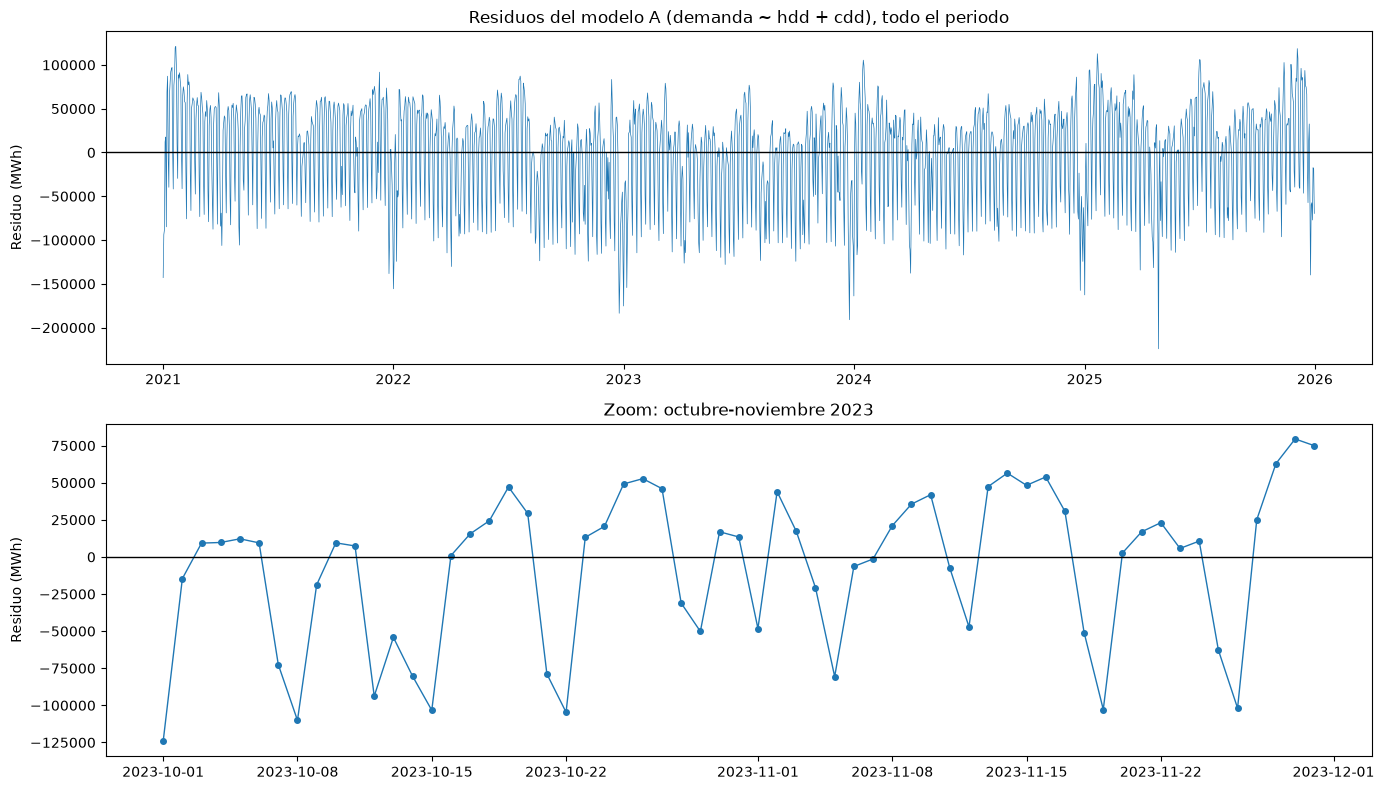

In [7]:
residuos = modelo_a.resid
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuos.index, residuos, linewidth=0.5)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuos del modelo A (demanda ~ hdd + cdd), todo el periodo")
axes[0].set_ylabel("Residuo (MWh)")

zoom = residuos.loc["2023-10":"2023-11"]
axes[1].plot(zoom.index, zoom, marker="o", markersize=4, linewidth=1)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Zoom: octubre-noviembre 2023")
axes[1].set_ylabel("Residuo (MWh)")

plt.tight_layout()
plt.show()

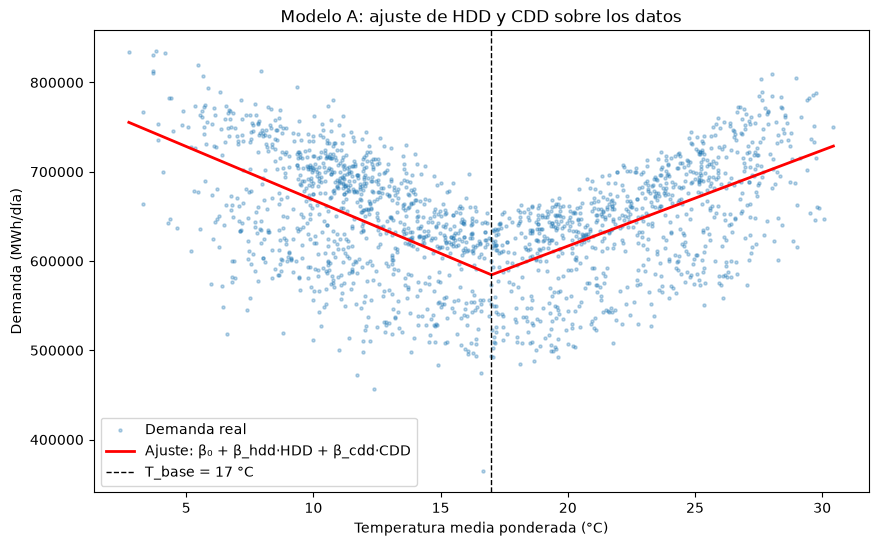

Intercept    584531.9
hdd           11980.4
cdd           10731.5
dtype: float64


In [8]:
t_base = CONFIG["peninsular"]["t_base"]

# 1. ordenar por temperatura para que la línea del ajuste se pinte bien
orden = df_peninsular["temperatura"].sort_values().index
ajuste = modelo_a.fittedvalues.loc[orden]

fig, ax = plt.subplots(figsize=(10, 6))

# 2. datos reales: un punto por día
ax.scatter(df_peninsular["temperatura"], df_peninsular["demanda_mwh"], s=5, alpha=0.3, label="Demanda real")

# 3. lo que predice el modelo
ax.plot(df_peninsular.loc[orden, "temperatura"], ajuste, color="red", linewidth=2,
        label="Ajuste: β₀ + β_hdd·HDD + β_cdd·CDD")

# 4. temperatura base: aquí HDD = CDD = 0
ax.axvline(t_base, color="black", linestyle="--", linewidth=1, label=f"T_base = {t_base} °C")

ax.set_xlabel("Temperatura media ponderada (°C)")
ax.set_ylabel("Demanda (MWh/día)")
ax.set_title("Modelo A: ajuste de HDD y CDD sobre los datos")
ax.legend()
plt.show()

# 5. las pendientes de la V
print(modelo_a.params.round(1))

## Segundo Modelo
demanda ~ hdd + cdd + C(dia_semana) + festivo

In [9]:
df_peninsular = cargar_sistema("peninsular")
df_peninsular = crear_features(df_peninsular, CONFIG["peninsular"]["t_base"],CONFIG["peninsular"]["subdiv"] )
modelo_b = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo", data=df_peninsular).fit()
print(modelo_b.params)
print(f"r squared= {modelo_b.rsquared}")

Intercept             597080.588556
C(dia_semana)[T.1]     18076.861986
C(dia_semana)[T.2]     22118.923557
C(dia_semana)[T.3]     21498.943944
C(dia_semana)[T.4]     14292.049893
C(dia_semana)[T.5]    -61218.332397
C(dia_semana)[T.6]   -100047.733796
hdd                    12558.367986
cdd                    10879.449229
festivo              -120183.012569
dtype: float64
r squared= 0.8009397067461621


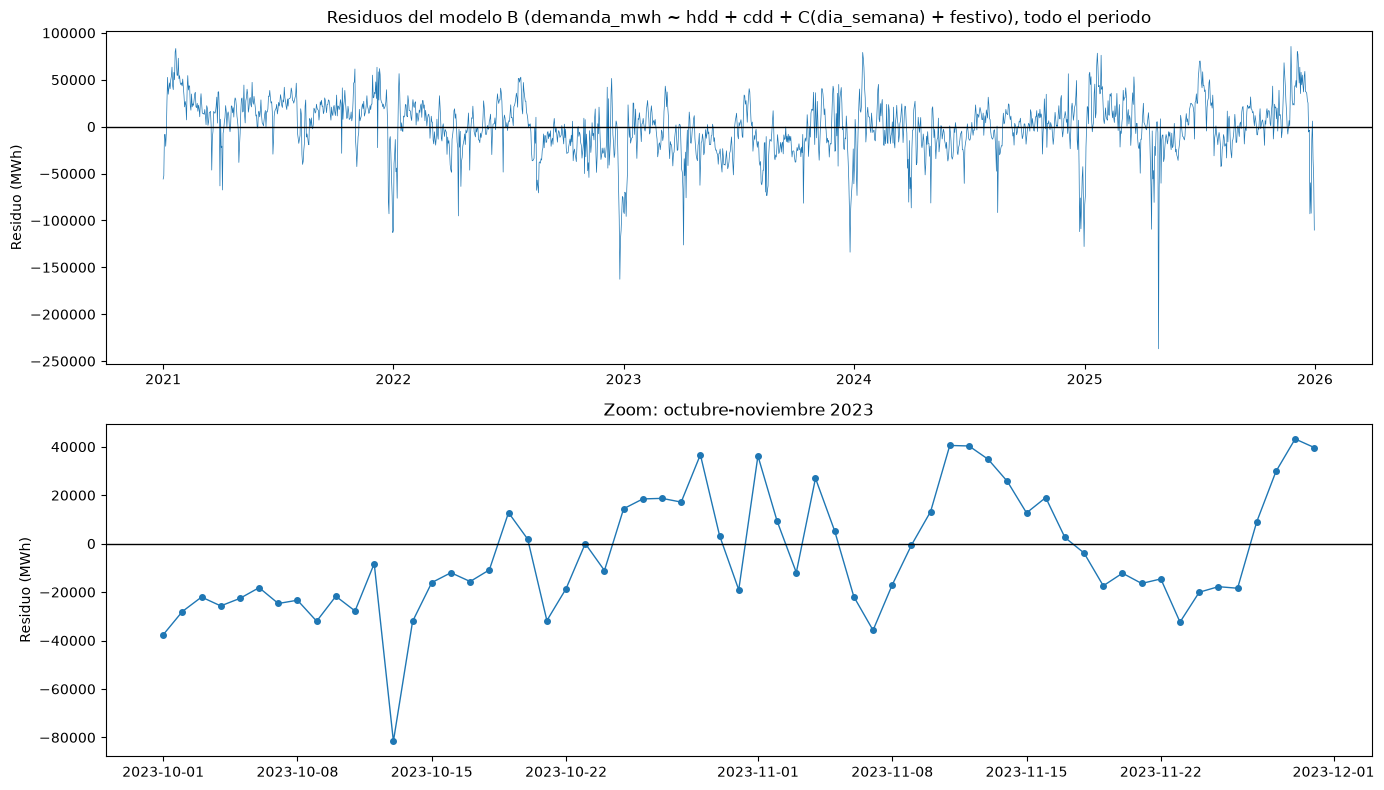

In [10]:
residuos = modelo_b.resid
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuos.index, residuos, linewidth=0.5)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuos del modelo B (demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo), todo el periodo")
axes[0].set_ylabel("Residuo (MWh)")

zoom = residuos.loc["2023-10":"2023-11"]
axes[1].plot(zoom.index, zoom, marker="o", markersize=4, linewidth=1)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Zoom: octubre-noviembre 2023")
axes[1].set_ylabel("Residuo (MWh)")

plt.tight_layout()
plt.show()

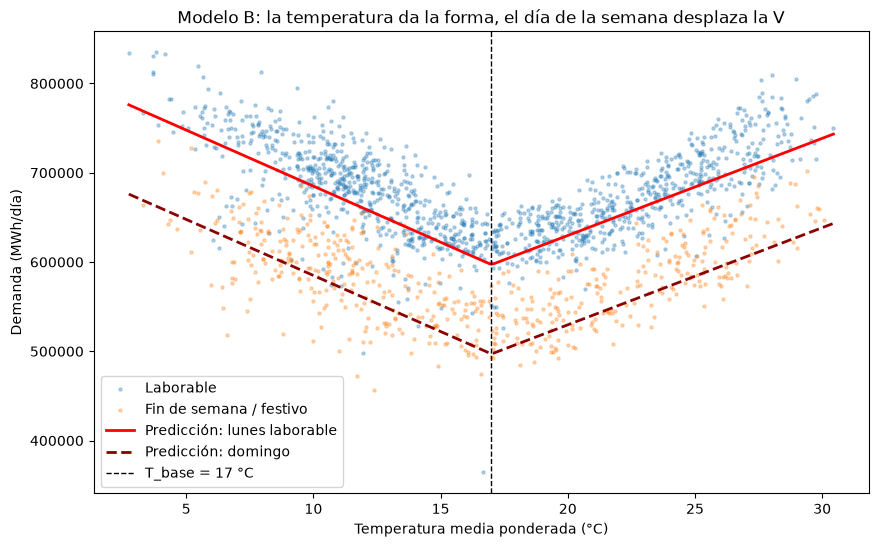

In [11]:
t_base = CONFIG["peninsular"]["t_base"]

# 1. rejilla de temperaturas y sus HDD/CDD
temp = np.linspace(df_peninsular["temperatura"].min(), df_peninsular["temperatura"].max(), 200)
hdd = np.maximum(t_base - temp, 0)
cdd = np.maximum(temp - t_base, 0)

# 2. predicción para un día de referencia (todas las columnas de la fórmula)
def predecir_dia(dia_semana, festivo=0):
    rejilla = pd.DataFrame({"hdd": hdd, "cdd": cdd, "dia_semana": dia_semana, "festivo": festivo})
    return modelo_b.predict(rejilla)

pred_lunes = predecir_dia(0)
pred_domingo = predecir_dia(6)

# 3. puntos reales separados: laborable normal vs. fin de semana o festivo
no_laborable = (df_peninsular["dia_semana"] >= 5) | (df_peninsular["festivo"] == 1)
lab = df_peninsular[~no_laborable]
finde = df_peninsular[no_laborable]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(lab["temperatura"], lab["demanda_mwh"], s=5, alpha=0.3, label="Laborable")
ax.scatter(finde["temperatura"], finde["demanda_mwh"], s=5, alpha=0.3, label="Fin de semana / festivo")

# 4. las dos V del modelo
ax.plot(temp, pred_lunes, color="red", linewidth=2, label="Predicción: lunes laborable")
ax.plot(temp, pred_domingo, color="darkred", linewidth=2, linestyle="--", label="Predicción: domingo")

ax.axvline(t_base, color="black", linestyle="--", linewidth=1, label=f"T_base = {t_base} °C")
ax.set_xlabel("Temperatura media ponderada (°C)")
ax.set_ylabel("Demanda (MWh/día)")
ax.set_title("Modelo B: la temperatura da la forma, el día de la semana desplaza la V")
ax.legend()
plt.show()

fecha
2021    2.61
2022   -0.96
2023   -2.09
2024   -0.65
2025    1.09
dtype: float64


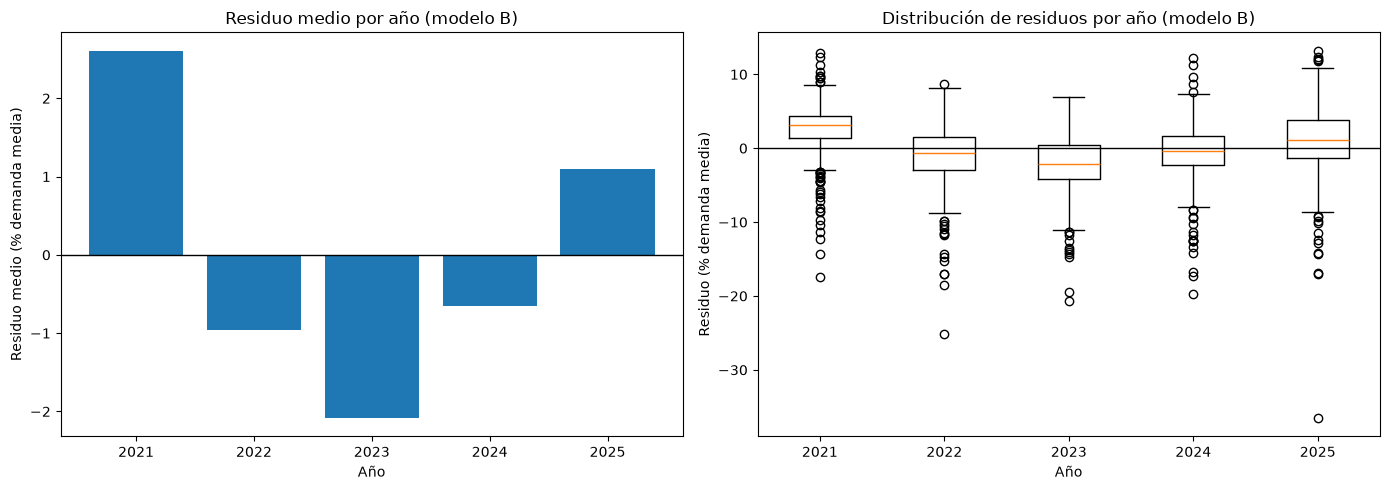

In [12]:
residuos = modelo_b.resid
demanda_media = df_peninsular["demanda_mwh"].mean()

# 1. residuos en % de la demanda media
residuos_pct = residuos / demanda_media * 100

# 2. media por año
media_anio = residuos_pct.groupby(residuos_pct.index.year).mean()
print(media_anio.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3. barras: residuo medio de cada año
axes[0].bar(media_anio.index, media_anio.values)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuo medio por año (modelo B)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Residuo medio (% demanda media)")

# 4. boxplot: dispersión de los residuos de cada año
anios = sorted(residuos_pct.index.year.unique())
datos_anio = [residuos_pct[residuos_pct.index.year == a] for a in anios]
axes[1].boxplot(datos_anio)
axes[1].set_xticks(range(1, len(anios) + 1), anios)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Distribución de residuos por año (modelo B)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Residuo (% demanda media)")

plt.tight_layout()
plt.show()

## Tercer Modelo
demanda ~ hdd + cdd + C(dia_semana) + festivo + C(anio)

El residuo medio por año del modelo B no es 0: cada año tiene su propio nivel de demanda por motivos que no son la temperatura. `C(anio)` le da a cada año su propio nivel (referencia: 2021).

In [13]:
modelo_c = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)", data=df_peninsular).fit()
print(modelo_c.params)
print(f"r squared= {modelo_c.rsquared}")

Intercept             614117.964706
C(dia_semana)[T.1]     18097.842941
C(dia_semana)[T.2]     22074.542962
C(dia_semana)[T.3]     21479.695947
C(dia_semana)[T.4]     14193.454688
C(dia_semana)[T.5]    -61175.049397
C(dia_semana)[T.6]    -99975.893127
C(anio)[T.2022]       -23238.728613
C(anio)[T.2023]       -30504.462492
C(anio)[T.2024]       -21181.027435
C(anio)[T.2025]        -9877.760003
hdd                    12467.000250
cdd                    10945.527809
festivo              -119157.234962
dtype: float64
r squared= 0.8271837717901762


In [14]:
# comparación de los tres modelos: ¿cambian las betas de temperatura al añadir controles?
modelos = {"A: hdd + cdd": modelo_a,
           "B: + día semana + festivo": modelo_b,
           "C: + año": modelo_c}

comparacion = pd.DataFrame({
    nombre: {"β_hdd": m.params["hdd"], "β_cdd": m.params["cdd"], "R²": m.rsquared}
    for nombre, m in modelos.items()
}).T
comparacion

,β_hdd,β_cdd,R²
A: hdd + cdd,11980.400097,10731.468485,0.304413
B: + día semana + festivo,12558.367986,10879.449229,0.800940
C: + año,12467.000250,10945.527809,0.827184


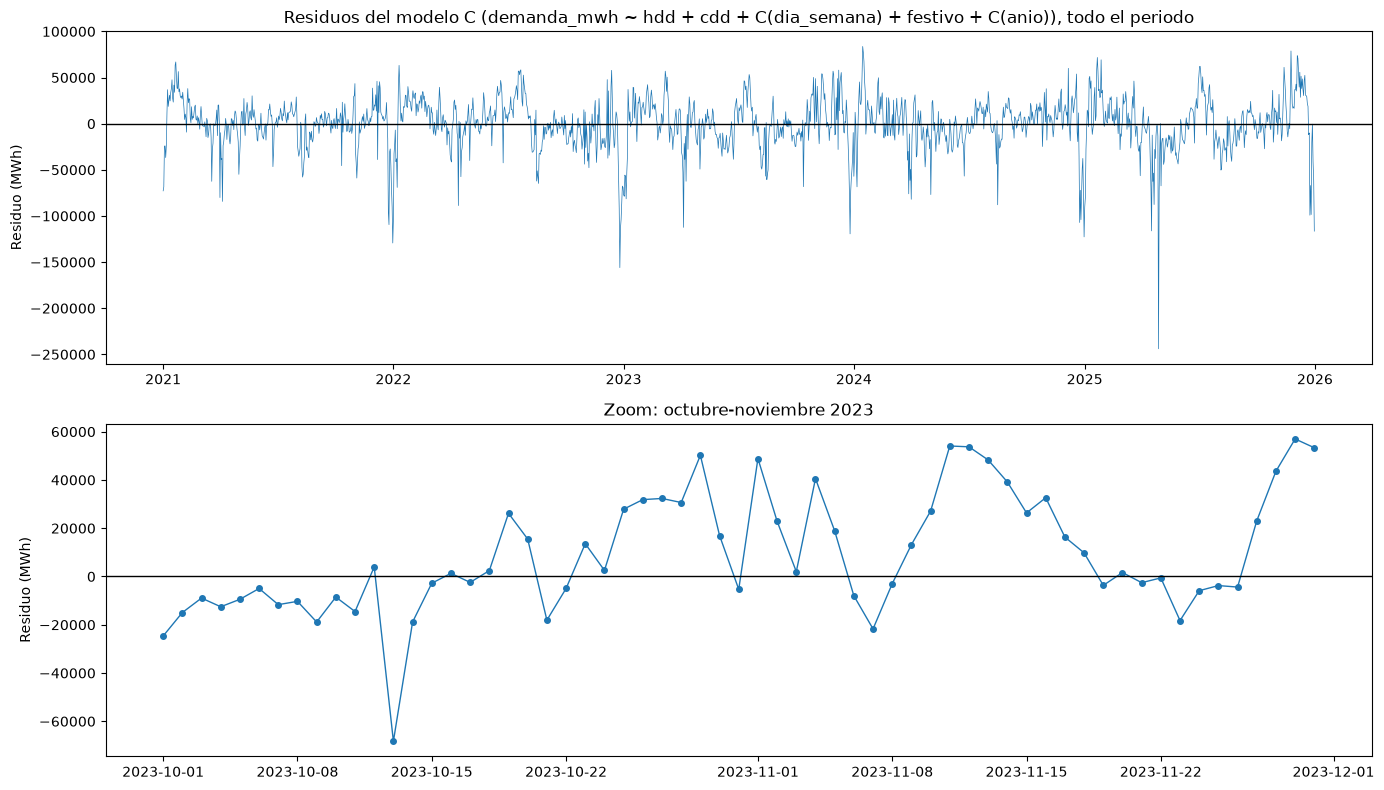

In [15]:
residuos = modelo_c.resid
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuos.index, residuos, linewidth=0.5)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuos del modelo C (demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)), todo el periodo")
axes[0].set_ylabel("Residuo (MWh)")

zoom = residuos.loc["2023-10":"2023-11"]
axes[1].plot(zoom.index, zoom, marker="o", markersize=4, linewidth=1)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Zoom: octubre-noviembre 2023")
axes[1].set_ylabel("Residuo (MWh)")

plt.tight_layout()
plt.show()

## Autocorrelación y errores HAC
Hasta aquí he mirado **cuánto valen** β_hdd y β_cdd. Ahora toca ver **cuánta seguridad** tengo en esos valores (su error estándar y su intervalo de confianza).

OLS calcula el error estándar suponiendo que **cada día es independiente**: que el error de hoy no dice nada del de mañana. Pero en los residuos se ven "olas" de varias semanas por encima o por debajo de 0: si hoy el modelo se queda corto, mañana probablemente también. Una ola de frío de 10 días se parece más a una sola observación que a 10 independientes. Por eso tengo **menos información de la que OLS cree**, y los intervalos clásicos salen **demasiado estrechos**.

1. **Diagnóstico**: residuo de hoy contra el de ayer, ACF (autocorrelación a 1, 2, … 30 días) y Durbin-Watson (2 = sin autocorrelación; cuanto más bajo, más autocorrelación positiva).
2. **Corrección**: errores estándar **HAC (Newey-West)**, que tienen en cuenta la correlación hasta `maxlags` días atrás. Uso 14 (dos semanas) porque la ACF tarda eso en caer a ~0. HAC **no cambia los coeficientes**, solo el error estándar y el IC.

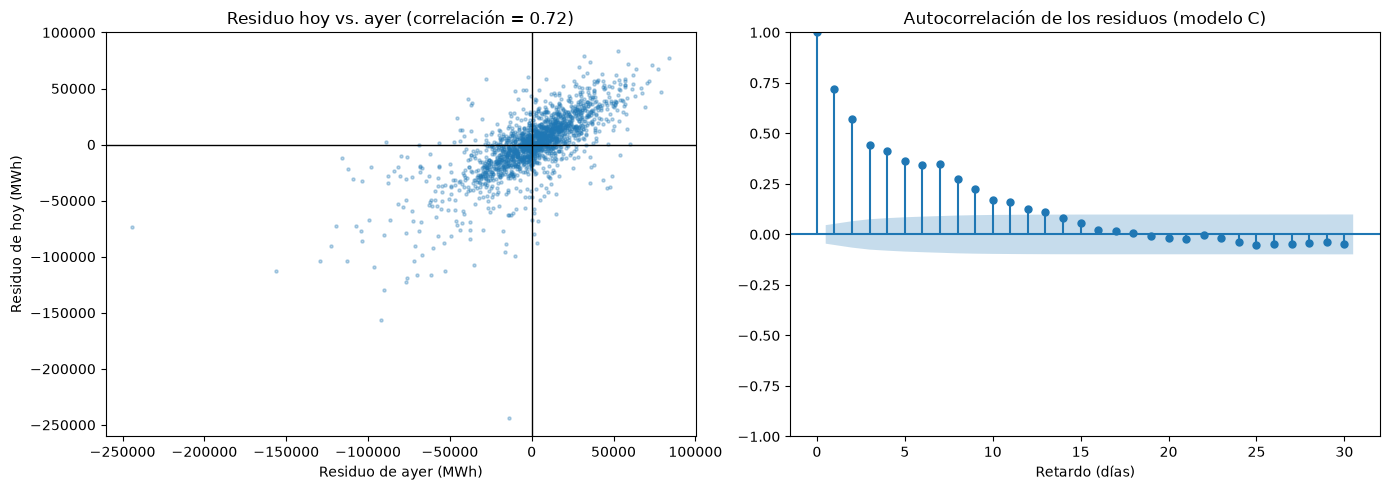

Durbin-Watson: 0.55


In [16]:
residuos = modelo_c.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. residuo de hoy contra el de ayer: nube redonda = independientes, diagonal = autocorrelación
ayer = residuos.shift(1)
corr = residuos.corr(ayer)
axes[0].scatter(ayer, residuos, s=5, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Residuo de ayer (MWh)")
axes[0].set_ylabel("Residuo de hoy (MWh)")
axes[0].set_title(f"Residuo hoy vs. ayer (correlación = {corr:.2f})")

# 2. ACF: la misma idea para 1, 2, ... 30 días atrás (fuera de la banda azul = significativa)
plot_acf(residuos, lags=30, ax=axes[1])
axes[1].set_xlabel("Retardo (días)")
axes[1].set_title("Autocorrelación de los residuos (modelo C)")

plt.tight_layout()
plt.show()

# 3. Durbin-Watson: 2 = sin autocorrelación, < 2 = autocorrelación positiva
dw = durbin_watson(residuos)
print(f"Durbin-Watson: {dw:.2f}")

In [17]:
MAXLAGS = 14  # la ACF tarda unas 2 semanas en caer a ~0 (a 7 días aún vale 0,35)

# 1. mismo modelo C, pero con errores estándar HAC (Newey-West)
modelo_c_hac = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)",
                       data=df_peninsular).fit(cov_type="HAC", cov_kwds={"maxlags": MAXLAGS})

# 2. coeficientes y errores estándar: los β deben ser idénticos, solo cambia el SE
variables = ["hdd", "cdd"]
tabla_se = pd.DataFrame({
    "β clásico": modelo_c.params[variables],
    "β HAC": modelo_c_hac.params[variables],
    "SE clásico": modelo_c.bse[variables],
    "SE HAC": modelo_c_hac.bse[variables],
})
tabla_se["ratio SE"] = tabla_se["SE HAC"] / tabla_se["SE clásico"]
print(tabla_se.round(1))

# 3. intervalos de confianza al 95 %, en % de la demanda media
ic_clasico = modelo_c.conf_int().loc[variables] / demanda_media * 100
ic_hac = modelo_c_hac.conf_int().loc[variables] / demanda_media * 100
ic = pd.concat({"IC 95% clásico": ic_clasico, "IC 95% HAC": ic_hac}, axis=1)
ic.columns = ic.columns.set_levels(["inf", "sup"], level=1)
print("\nIntervalo de confianza del efecto por grado-día (% de la demanda media):")
print(ic.round(3))

     β clásico    β HAC  SE clásico  SE HAC  ratio SE
hdd    12467.0  12467.0       229.7   574.8       2.5
cdd    10945.5  10945.5       222.8   577.2       2.6

Intervalo de confianza del efecto por grado-día (% de la demanda media):
    IC 95% clásico        IC 95% HAC       
               inf    sup        inf    sup
hdd          1.854  1.993      1.749  2.097
cdd          1.621  1.756      1.514  1.863


## Estacionalidad que no es temperatura
Hay cosas que cambian con el mes y no son la temperatura: las **horas de luz** (en diciembre se enciende la luz mucho antes que en junio), las **vacaciones** (en agosto paran la industria y muchas oficinas), el **turismo** o la **Navidad** más allá de los festivos. El modelo C no tiene ninguna variable para esto, y si existe se mezcla con HDD/CDD, porque también dependen del mes: en invierno hace frío **y** hay menos luz.

1. **Diagnóstico**: residuo medio por mes del modelo C. Si el modelo solo necesitara la temperatura, todas las barras rondarían 0. Me fijo sobre todo en **julio frente a agosto**: hace el mismo calor, así que deberían salir parecidos.
2. **Variante con `C(mes)`** (modelo D, referencia: enero). Con efectos fijos de mes, el modelo solo aprende el efecto de la temperatura **comparando días del mismo mes** (un enero más frío de lo normal contra un enero normal).

Ninguna de las dos variantes es la verdad absoluta:
- **Sin mes** (C): el efecto de la temperatura puede incluir cosas que no son temperatura (luz, vacaciones).
- **Con mes** (D): quita esas cosas, pero también se lleva parte de la variación real de temperatura ("enero es frío" lo absorbe el mes, no HDD). Puede estar **sobrecontrolando**.

Lo honesto es dar las dos como un **rango**.

fecha
1     1.72
2     1.97
3     0.23
4    -2.29
5    -1.11
6    -0.31
7     2.73
8    -2.51
9     0.02
10   -0.04
11    0.93
12   -1.21
dtype: float64


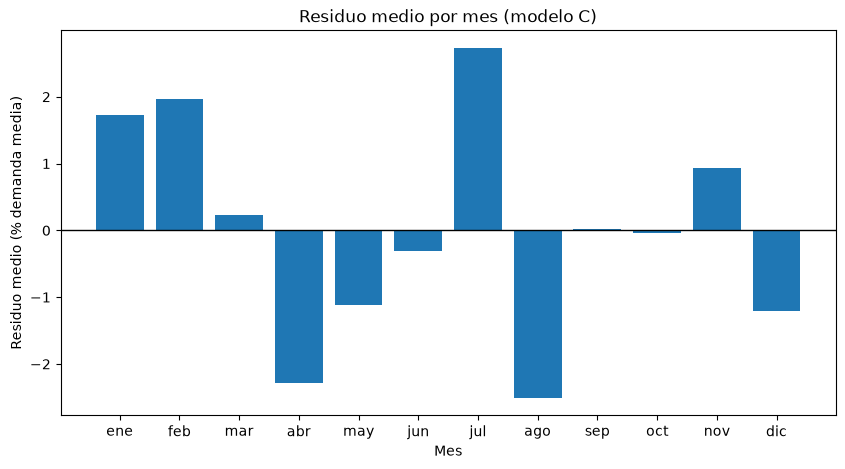

In [18]:
# 1. residuo medio de cada mes del modelo C, en % de la demanda media
residuos_pct = modelo_c.resid / demanda_media * 100
media_mes = residuos_pct.groupby(residuos_pct.index.month).mean()
print(media_mes.round(2))

# 2. barras: un mes lejos de 0 = algo que el modelo no recoge
nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(nombres_mes, media_mes.values)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Residuo medio por mes (modelo C)")
ax.set_xlabel("Mes")
ax.set_ylabel("Residuo medio (% demanda media)")
plt.show()

In [19]:
df_peninsular["mes"] = df_peninsular.index.month

# 1. modelo D: el C + efectos fijos de mes (referencia: enero), con los mismos errores HAC
modelo_d_hac = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio) + C(mes)",
                       data=df_peninsular).fit(cov_type="HAC", cov_kwds={"maxlags": MAXLAGS})

# 2. efecto por grado-día en % de la demanda media, con su IC 95 % HAC, para las dos variantes
def efectos_pct(res):
    ic = res.conf_int()
    fila = {}
    for var in ["hdd", "cdd"]:
        fila[f"{var} %"] = res.params[var] / demanda_media * 100
        fila[f"{var} IC inf"] = ic.loc[var, 0] / demanda_media * 100
        fila[f"{var} IC sup"] = ic.loc[var, 1] / demanda_media * 100
    fila["R²"] = res.rsquared
    return fila

variantes = pd.DataFrame({
    "C: sin mes": efectos_pct(modelo_c_hac),
    "D: con C(mes)": efectos_pct(modelo_d_hac),
}).T
variantes.round(3)

,hdd %,hdd IC inf,hdd IC sup,cdd %,cdd IC inf,cdd IC sup,R²
C: sin mes,1.923,1.749,2.097,1.689,1.514,1.863,0.827
D: con C(mes),1.425,1.176,1.673,1.766,1.568,1.963,0.858


## Otros sistemas: Baleares y Canarias
Hasta aquí todo ha sido con la península. Ahora aplico el mismo modelo (variantes C y D, con errores HAC) a los otros dos sistemas, pero cada uno tiene su propio problema:

- **Baleares: el turismo.** En verano hay muchísima más gente en las islas, y el turismo llega **a la vez** que el calor. Sin `C(mes)`, CDD puede llevarse el mérito del turismo, así que aquí la diferencia entre las dos variantes debería ser mayor que en la península.
- **Canarias: casi no hace frío.** Con `t_base = 16` apenas hay días con HDD > 0, y en esos días HDD es muy pequeño. Para estimar una pendiente la variable tiene que moverse; si HDD es casi siempre 0, su coeficiente sale con un intervalo enorme. No es que el frío no importe, es que **no hay datos para medirlo**, así que en Canarias el modelo va sin `hdd`.

Pasos:
1. **Descriptivo**: perfil de demanda por mes de los tres sistemas y cuánto se mueven HDD y CDD en cada uno.
2. **El problema de Canarias**: ajusto el modelo con `hdd` para ver su intervalo.
3. **Tabla final**: los tres sistemas con las dos variantes, efectos en % de la demanda media e IC 95 % HAC.

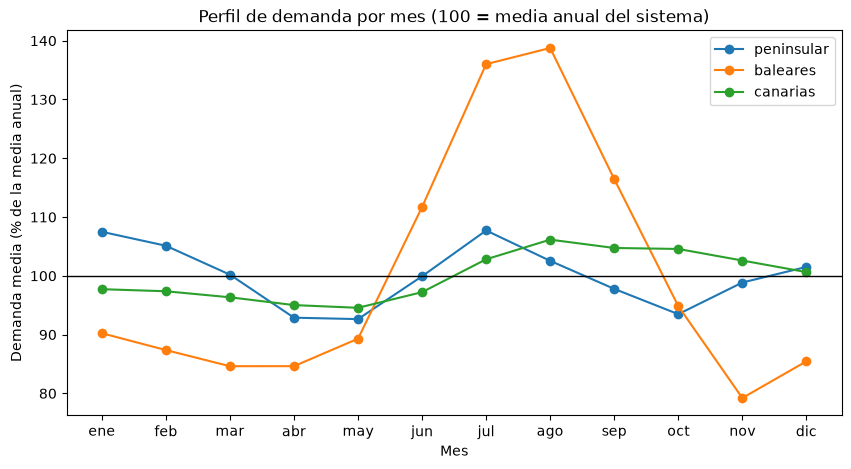

,t_base,temp mín,temp máx,días HDD > 0,HDD medio en esos días,días CDD > 0
peninsular,17.0,2.7,30.4,974.0,5.5,852.0
baleares,16.0,5.4,31.9,721.0,3.3,1105.0
canarias,16.0,13.0,30.9,42.0,0.7,1784.0


In [20]:
# 1. cargar los tres sistemas con sus features (cada uno con su t_base y sus festivos)
datos = {}
for sistema, cfg in CONFIG.items():
    df = crear_features(cargar_sistema(sistema), **cfg)
    df["mes"] = df.index.month
    datos[sistema] = df

# 2. perfil mensual: demanda media de cada mes en % de la media anual del sistema
fig, ax = plt.subplots(figsize=(10, 5))
for sistema, df in datos.items():
    perfil = df["demanda_mwh"].groupby(df["mes"]).mean() / df["demanda_mwh"].mean() * 100
    ax.plot(nombres_mes, perfil.values, marker="o", label=sistema)
ax.axhline(100, color="black", linewidth=1)
ax.set_title("Perfil de demanda por mes (100 = media anual del sistema)")
ax.set_xlabel("Mes")
ax.set_ylabel("Demanda media (% de la media anual)")
ax.legend()
plt.show()

# 3. cuánto se mueven HDD y CDD en cada sistema
resumen = pd.DataFrame({
    sistema: {
        "t_base": CONFIG[sistema]["t_base"],
        "temp mín": df["temperatura"].min(),
        "temp máx": df["temperatura"].max(),
        "días HDD > 0": (df["hdd"] > 0).sum(),
        "HDD medio en esos días": df.loc[df["hdd"] > 0, "hdd"].mean(),
        "días CDD > 0": (df["cdd"] > 0).sum(),
    }
    for sistema, df in datos.items()
}).T
resumen.round(1)

In [21]:
# Canarias CON hdd: ¿se puede estimar el efecto del frío?
df_can = datos["canarias"]
dm_can = df_can["demanda_mwh"].mean()
res_can = smf.ols("demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)",
                  data=df_can).fit(cov_type="HAC", cov_kwds={"maxlags": MAXLAGS})

# efecto por grado-día en % y su IC 95 % HAC: fíjate en lo ancho que sale el de hdd
canarias_hdd = res_can.conf_int().loc[["hdd", "cdd"]] / dm_can * 100
canarias_hdd.columns = ["IC inf", "IC sup"]
canarias_hdd.insert(0, "efecto %", res_can.params[["hdd", "cdd"]] / dm_can * 100)
canarias_hdd["ancho IC"] = canarias_hdd["IC sup"] - canarias_hdd["IC inf"]
canarias_hdd.round(2)

,efecto %,IC inf,IC sup,ancho IC
hdd,2.39,0.19,4.59,4.40
cdd,1.28,1.11,1.45,0.34


In [22]:
# 1. fórmula de cada sistema: Canarias sin hdd (casi no varía), y C(mes) solo en la variante "mes"
def formula_sistema(sistema, con_mes):
    controles = "cdd + C(dia_semana) + festivo + C(anio)"
    if sistema != "canarias":
        controles = "hdd + " + controles
    if con_mes:
        controles += " + C(mes)"
    return "demanda_mwh ~ " + controles

# 2. efecto por grado-día en % con su IC 95 % (NaN si la variable no está en el modelo)
def efectos_sistema(res, dem_media):
    ic = res.conf_int()
    fila = {}
    for var in ["hdd", "cdd"]:
        if var in res.params.index:
            fila[f"{var} %"] = res.params[var] / dem_media * 100
            fila[f"{var} IC inf"] = ic.loc[var, 0] / dem_media * 100
            fila[f"{var} IC sup"] = ic.loc[var, 1] / dem_media * 100
        else:
            fila[f"{var} %"] = fila[f"{var} IC inf"] = fila[f"{var} IC sup"] = np.nan
    fila["R²"] = res.rsquared
    return fila

# 3. los tres sistemas x las dos variantes (base = C, mes = D), todos con HAC
filas = {}
for sistema, df in datos.items():
    for variante, con_mes in VARIANTES.items():
        res = smf.ols(formula_sistema(sistema, con_mes), data=df).fit(
            cov_type="HAC", cov_kwds={"maxlags": MAXLAGS})
        filas[(sistema, variante)] = efectos_sistema(res, df["demanda_mwh"].mean())

tabla_final = pd.DataFrame(filas).T
tabla_final.index.names = ["sistema", "variante"]
tabla_final.round(2)

hdd %  hdd IC inf  hdd IC sup  cdd %  cdd IC inf  \
sistema    variante                                                     
peninsular base       1.92        1.75        2.10   1.69        1.51   
           mes        1.42        1.18        1.67   1.77        1.57   
baleares   base       3.53        3.12        3.95   5.18        4.90   
           mes        3.14        2.77        3.50   3.55        3.02   
canarias   base        NaN         NaN         NaN   1.26        1.08   
           mes         NaN         NaN         NaN   0.90        0.69   

                     cdd IC sup    R²  
sistema    variante                    
peninsular base            1.86  0.83  
           mes             1.96  0.86  
baleares   base            5.46  0.89  
           mes             4.07  0.93  
canarias   base            1.43  0.78  
           mes             1.11  0.90

## Conclusiones

### La pregunta
¿Cuánto sube la demanda eléctrica diaria por cada grado que la temperatura se aleja de la de confort, separando el frío (HDD) del calor (CDD), en cada uno de los tres sistemas (2021-2025)?

### Cómo he llegado al modelo
He ido de lo más simple a lo completo, añadiendo cada pieza solo cuando una gráfica mostraba que hacía falta:

| Modelo | Qué añado | Qué lo motivó | Efecto en la península |
|---|---|---|---|
| A | `hdd + cdd` | La U de temperatura contra demanda: una recta no sirve | R² = 0,30 |
| B | `C(dia_semana) + festivo` | Dientes de sierra semanales y valles en festivos en los residuos | R² = 0,80; las betas casi no cambian (el día de la semana no está relacionado con la temperatura) |
| C | `C(anio)` | Residuo medio distinto de 0 según el año (2023 el más bajo) | R² = 0,83; betas estables |
| C con HAC | Errores HAC (`maxlags=14`) | Residuos autocorrelacionados (DW = 0,55): OLS se pasaba de confiado | Mismas betas; error estándar unas 2,5 veces mayor |
| D | `C(mes)` | Residuo medio por mes: julio +2,7 %, agosto −2,5 % (vacaciones) | El efecto del frío baja de 1,92 % a 1,42 % |

Por el camino también corregí `festivo`, que contaba dos veces los festivos que caen en fin de semana.

### Resultado: efecto por grado-día (% de la demanda media, IC 95 % HAC)
| Sistema | Frío (HDD) | Calor (CDD) |
|---|---|---|
| Península | 1,4 % – 1,9 % | 1,7 % – 1,8 % |
| Baleares | 3,1 % – 3,5 % | 3,6 % – 5,2 % |
| Canarias | no medible | 0,9 % – 1,3 % |

Cada rango va del valor con `C(mes)` (modelo D) al valor sin `C(mes)` (modelo C). Los IC de cada variante están en `tabla_final`.

### Qué me dice
- **La temperatura importa en los tres sistemas**: todos los efectos son claramente significativos, incluso con errores HAC.
- **Península**: el calor es un resultado sólido (no depende de la variante). El frío depende de cuánto de la estacionalidad de invierno (menos luz, Navidad) atribuya a la temperatura. Con estos datos no puedo afirmar si pesa más el frío o el calor.
- **Baleares** es el sistema más sensible, unas dos veces más que la península. Sin `C(mes)`, el calor se lleva parte del efecto del turismo de verano (5,2 % → 3,6 % al meter el mes).
- **Canarias** es el menos sensible al calor, y el frío no se puede medir: solo 42 días con HDD > 0 en 5 años, con un HDD medio de 0,7 grados (el IC con `hdd` iba del 0,2 % al 4,6 %).

### Limitaciones
- **Festivos incompletos**: en la península solo uso los nacionales. Faltan los autonómicos (Jueves Santo, el 26/12/2022…), los puentes y los días "casi festivos" (24 y 31 de diciembre), que siguen apareciendo entre los peores residuos.
- **Outliers sin tratar**: el apagón del 28/04/2025 es el peor residuo de todo el periodo.
- **T_base fija** (17 °C en la península y 16 °C en las islas), elegida a mano y no estimada.
- **Efecto lineal**: supongo que cada grado-día suma lo mismo. Un día extremo podría pesar más que uno suave, y la inercia térmica (el calor de ayer) no está en el modelo.
- **Autoconsumo**: la demanda de REE no ve la energía de las placas solares en tejados, que crece cada año. `C(anio)` recoge su nivel, pero no cómo cambia según la temperatura.
- **Modelo explicativo**: mide sensibilidades, no predice la demanda ni el efecto del cambio climático a largo plazo.

### Posibles mejoras
- Añadir festivos autonómicos ponderados por población y una variable para Navidad y puentes.
- Estimar T_base probando varios valores y quedándome con el que mejor ajuste.
- Añadir la temperatura de días anteriores (retardos de HDD/CDD) para recoger la inercia térmica.
- Probar efectos no lineales (por ejemplo, HDD² y CDD²) para los días extremos.